## 1. Load the saved data

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

path = Path("outputs/caltech_occupancy_data.npz")

with np.load(path, allow_pickle=False) as data:
    X_test = data["test_X_hist"].copy()
    y_test = data["test_y"].copy()

    timestamps = data["timestamps"].copy()
    test_origins = data["test_origins"].copy()

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Test samples:", len(y_test))

X_test: (12102, 672)
y_test: (12102, 16)
Test samples: 12102


## 2. Generate the two baseline forecasts
Persistence: every future step equals the most recent occupancy.

Seasonal naive: each future step equals the occupancy at the same time one week earlier.

In [3]:
H = 16
L = 672

# Persistence: repeat the most recent observation.
y_pred_persistence = np.repeat(
    X_test[:, -1:],
    H,
    axis=1
)

# Seasonal naive: use the final 16 observations of the
# one-week history, corresponding to the same time last week.
y_pred_seasonal = X_test[:, :H]

print("Persistence:", y_pred_persistence.shape)
print("Seasonal naive:", y_pred_seasonal.shape)

Persistence: (12102, 16)
Seasonal naive: (12102, 16)


## 3. Evaluate MAE and RMSE per horizon

In [4]:
def evaluate_forecast(y_true, y_pred, name):
    errors = y_true - y_pred

    mae = np.mean(np.abs(errors), axis=0)
    rmse = np.sqrt(np.mean(errors**2, axis=0))

    results = pd.DataFrame({
        "horizon_minutes": np.arange(1, y_true.shape[1] + 1) * 15,
        "MAE": mae,
        "RMSE": rmse,
    })

    print(f"\n{name}")
    display(results.round(4))

    return results


results_persistence = evaluate_forecast(
    y_test, y_pred_persistence, "Persistence"
)

results_seasonal = evaluate_forecast(
    y_test, y_pred_seasonal, "Seasonal naive"
)


Persistence


,horizon_minutes,MAE,RMSE
0,15,0.2751,0.5977
1,30,0.4769,0.8744
2,45,0.6408,1.1052
3,60,0.7818,1.3073
4,75,0.8992,1.4871
5,90,1.0092,1.6568
6,105,1.1091,1.8165
7,120,1.2072,1.9706
8,135,1.3048,2.1174
9,150,1.4015,2.2584



Seasonal naive


,horizon_minutes,MAE,RMSE
0,15,1.2143,1.9730
1,30,1.2148,1.9740
2,45,1.2153,1.9750
3,60,1.2158,1.9760
4,75,1.2162,1.9765
5,90,1.2166,1.9769
6,105,1.2170,1.9774
7,120,1.2173,1.9779
8,135,1.2176,1.9782
9,150,1.2178,1.9784


In [5]:
comparison = pd.DataFrame({
    "Persistence_MAE": results_persistence["MAE"].values,
    "Seasonal_MAE": results_seasonal["MAE"].values,
})

comparison["horizon_minutes"] = results_persistence["horizon_minutes"]

display(
    comparison.loc[
        comparison["horizon_minutes"].isin([60, 240]),
        ["horizon_minutes", "Persistence_MAE", "Seasonal_MAE"]
    ].round(4)
)

,horizon_minutes,Persistence_MAE,Seasonal_MAE
3,60,0.7818,1.2158
15,240,1.9369,1.2179


## 4. Baseline comparison

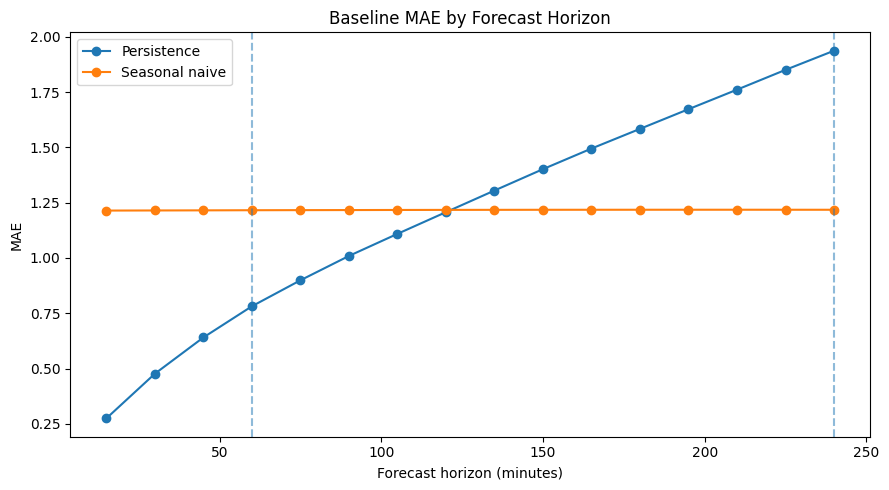

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    results_persistence["horizon_minutes"],
    results_persistence["MAE"],
    marker="o",
    label="Persistence"
)

plt.plot(
    results_seasonal["horizon_minutes"],
    results_seasonal["MAE"],
    marker="o",
    label="Seasonal naive"
)

plt.axvline(60, linestyle="--", alpha=0.5)
plt.axvline(240, linestyle="--", alpha=0.5)

plt.xlabel("Forecast horizon (minutes)")
plt.ylabel("MAE")
plt.title("Baseline MAE by Forecast Horizon")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
import numpy as np
import pandas as pd

path = Path("outputs/caltech_occupancy_data.npz")

with np.load(path, allow_pickle=False) as data:
    train_X_hist = data["train_X_hist"]
    train_X_cal  = data["train_X_cal"]
    y_train      = data["train_y"]

    val_X_hist = data["val_X_hist"]
    val_X_cal  = data["val_X_cal"]
    y_val      = data["val_y"]

    test_X_hist = data["test_X_hist"]
    test_X_cal  = data["test_X_cal"]
    y_test      = data["test_y"]

H = y_train.shape[1]
L = train_X_hist.shape[1]
C = train_X_cal.shape[2]

In [ ]:
# from sklearn.linear_model import Ridge
# from sklearn.preprocessing import StandardScaler

# def make_features(hist, cal):
#     return np.concatenate([hist, cal.reshape(len(cal), -1)], axis=1)

# ridge_scaler = StandardScaler()
# Xr_train = ridge_scaler.fit_transform(make_features(train_X_hist, train_X_cal))
# Xr_val   = ridge_scaler.transform(make_features(val_X_hist, val_X_cal))
# Xr_test  = ridge_scaler.transform(make_features(test_X_hist, test_X_cal))
# ridge = Ridge(alpha=10.0, solver="lsqr")

# ridge.fit(Xr_train, y_train)


# ridge_val_pred = ridge.predict(Xr_val)
# ridge_test_pred = ridge.predict(Xr_test)